Mở lại kết nối & Đọc bảng dữ liệu sạch

In [2]:
!pip install -q pyspark matplotlib seaborn

import os
from google.colab import drive
drive.mount('/content/drive')

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder
    .appName("NYCTaxi_Huyen_Clean")
    .config("spark.sql.shuffle.partitions", "64")
    .getOrCreate()
)

# Thư mục chứa dữ liệu Parquet trên Drive của bạn
folder_path = "/content/drive/MyDrive/DoAnBigData"

# Lấy danh sách các file .parquet trong thư mục (loại trùng tên nếu có)
all_parquet = sorted([
    os.path.join(folder_path, f)
    for f in os.listdir(folder_path)
    if f.endswith(".parquet")
])
print("Các file tìm thấy:", len(all_parquet))
for p in all_parquet:
    print(" -", p)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Các file tìm thấy: 15
 - /content/drive/MyDrive/DoAnBigData/yellow_tripdata_2024-11.parquet
 - /content/drive/MyDrive/DoAnBigData/yellow_tripdata_2024-12.parquet
 - /content/drive/MyDrive/DoAnBigData/yellow_tripdata_2025-01.parquet
 - /content/drive/MyDrive/DoAnBigData/yellow_tripdata_2025-02.parquet
 - /content/drive/MyDrive/DoAnBigData/yellow_tripdata_2025-03.parquet
 - /content/drive/MyDrive/DoAnBigData/yellow_tripdata_2025-04.parquet
 - /content/drive/MyDrive/DoAnBigData/yellow_tripdata_2025-05.parquet
 - /content/drive/MyDrive/DoAnBigData/yellow_tripdata_2025-06 (1).parquet
 - /content/drive/MyDrive/DoAnBigData/yellow_tripdata_2025-06.parquet
 - /content/drive/MyDrive/DoAnBigData/yellow_tripdata_2025-07.parquet
 - /content/drive/MyDrive/DoAnBigData/yellow_tripdata_2025-08.parquet
 - /content/drive/MyDrive/DoAnBigData/yellow_tripdata_2025-09.parquet
 - /c

Làm sạch dữ liệu & Lưu bản sạch

In [3]:
required_cols = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "passenger_count",
    "trip_distance",
    "PULocationID",
    "DOLocationID",
    "payment_type",
    "fare_amount",
    "tip_amount",
    "total_amount",
]

# Chọn các file năm 2025 (bỏ bản trùng nếu có)
files_2025 = [
    os.path.join(folder_path, f"yellow_tripdata_2025-{m:02d}.parquet")
    for m in range(1, 13)
    if os.path.exists(os.path.join(folder_path, f"yellow_tripdata_2025-{m:02d}.parquet"))
]

df_raw = (
    spark.read.parquet(*files_2025)
    .select(*required_cols)
    .withColumn("tpep_pickup_datetime", F.to_timestamp("tpep_pickup_datetime"))
    .withColumn("tpep_dropoff_datetime", F.to_timestamp("tpep_dropoff_datetime"))
    .withColumn("passenger_count", F.col("passenger_count").cast("int"))
    .withColumn("trip_distance", F.col("trip_distance").cast("double"))
    .withColumn("PULocationID", F.col("PULocationID").cast("int"))
    .withColumn("DOLocationID", F.col("DOLocationID").cast("int"))
    .withColumn("payment_type", F.col("payment_type").cast("int"))
    .withColumn("fare_amount", F.col("fare_amount").cast("double"))
    .withColumn("tip_amount", F.col("tip_amount").cast("double"))
    .withColumn("total_amount", F.col("total_amount").cast("double"))
)

print("Số dòng trước làm sạch:", df_raw.count())

df_clean = (
    df_raw.dropna(subset=required_cols)
    .filter(F.col("tpep_dropoff_datetime") > F.col("tpep_pickup_datetime"))
    .filter((F.col("trip_distance") > 0) & (F.col("trip_distance") < 100))
    .filter((F.col("passenger_count") >= 1) & (F.col("passenger_count") <= 6))
    .filter((F.col("total_amount") > 0) & (F.col("total_amount") < 500))
    .filter(F.col("tip_amount") >= 0)
    .filter(F.col("fare_amount") > 0)
)

# Lưu dữ liệu sạch vào thư mục DoAnBigData trên Drive của bạn
clean_out_path = "/content/drive/MyDrive/DoAnBigData/taxi_clean_2025"
df_clean.coalesce(12).write.mode("overwrite").parquet(clean_out_path)

bang = spark.read.parquet(clean_out_path)
print("Số dòng sau làm sạch (đã lưu):", bang.count())
bang.show(5, truncate=False)

Số dòng trước làm sạch: 48722602
Số dòng sau làm sạch (đã lưu): 35074288
+--------------------+---------------------+---------------+-------------+------------+------------+------------+-----------+----------+------------+
|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|PULocationID|DOLocationID|payment_type|fare_amount|tip_amount|total_amount|
+--------------------+---------------------+---------------+-------------+------------+------------+------------+-----------+----------+------------+
|2025-02-01 00:12:18 |2025-02-01 00:32:33  |3              |3.12         |246         |79          |1           |19.8       |5.11      |30.66       |
|2025-02-01 00:40:04 |2025-02-01 00:49:15  |1              |1.4          |114         |79          |1           |10.0       |3.15      |18.9        |
|2025-02-01 00:02:52 |2025-02-01 00:20:25  |1              |4.19         |113         |263         |1           |19.8       |5.11      |30.66       |
|2025-02-01 00:33:47 |2025-

Phân tích mô tả bằng Spark SQL (Bài toán 1 trong thuyết minh)

In [5]:
!pip install -q pyspark matplotlib seaborn

from google.colab import drive
drive.mount('/content/drive')

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
import matplotlib.pyplot as plt
import seaborn as sns

spark = (
    SparkSession.builder
    .appName("NYCTaxi_Analysis_ML")
    .config("spark.sql.shuffle.partitions", "64")
    .getOrCreate()
)

# Đọc trực tiếp bảng 12 tháng đã làm sạch từ đúng đường dẫn
bang = spark.read.parquet("/content/drive/MyDrive/DoAnBigData/taxi_clean_2025")
print("Tổng số dòng sạch:", bang.count())
bang.printSchema()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Tổng số dòng sạch: 35074288
root
 |-- tpep_pickup_datetime: timestamp (nullable = true)
 |-- tpep_dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: integer (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- total_amount: double (nullable = true)



Trực quan hóa dữ liệu bằng

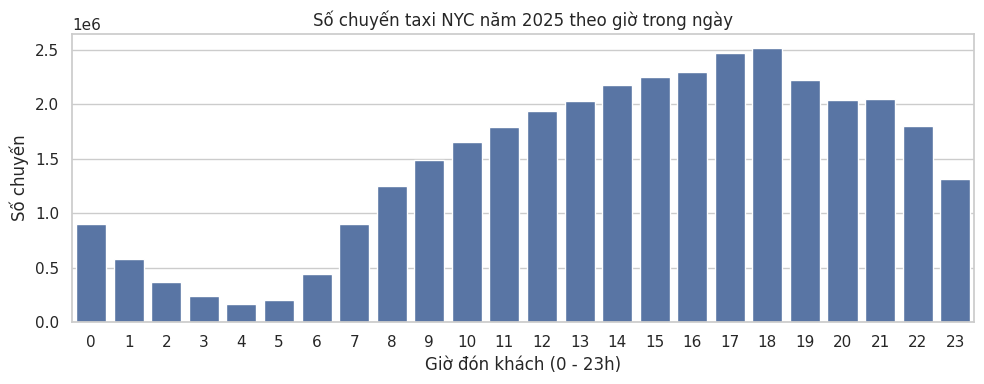

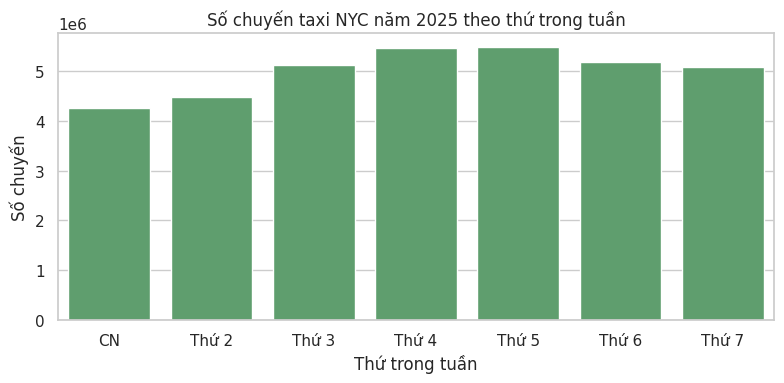

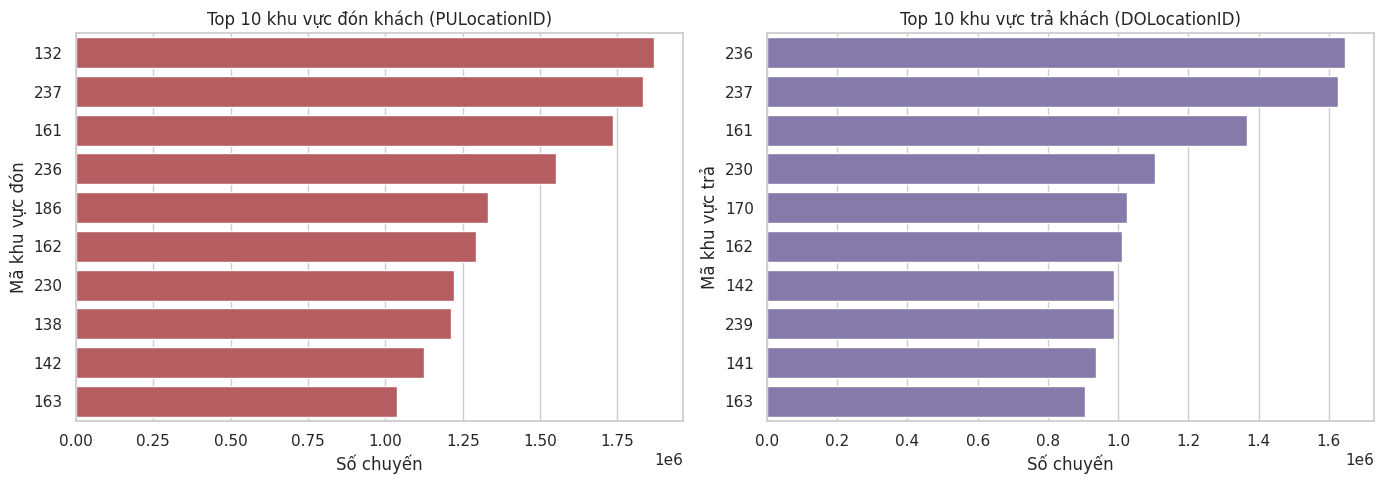

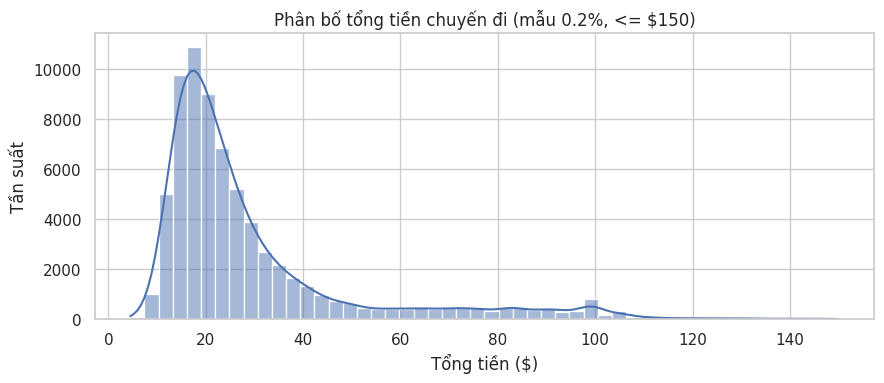

In [7]:
sns.set_theme(style="whitegrid")

# --- 1. Tạo các DataFrame gom nhóm (Aggregations) từ bảng sạch 'bang' ---
# Đếm số chuyến theo giờ
df_gio = (
    bang
    .withColumn("gio_don", F.hour("tpep_pickup_datetime"))
    .groupBy("gio_don")
    .count()
    .withColumnRenamed("count", "so_chuyen")
    .orderBy("gio_don")
)

# Đếm số chuyến theo thứ trong tuần
df_thu = (
    bang
    .withColumn("thu_trong_tuan", F.dayofweek("tpep_pickup_datetime"))
    .groupBy("thu_trong_tuan")
    .count()
    .withColumnRenamed("count", "so_chuyen")
    .orderBy("thu_trong_tuan")
)

# Top 10 điểm đón
df_top_don = (
    bang
    .groupBy("PULocationID")
    .count()
    .withColumnRenamed("count", "so_chuyen_don")
    .orderBy(F.desc("so_chuyen_don"))
    .limit(10)
)

# Top 10 điểm trả
df_top_tra = (
    bang
    .groupBy("DOLocationID")
    .count()
    .withColumnRenamed("count", "so_chuyen_tra")
    .orderBy(F.desc("so_chuyen_tra"))
    .limit(10)
)

# Đường dẫn thư mục lưu ảnh biểu đồ
img_save_dir = "/content/drive/MyDrive/DoAnBigData/"

# --- 2. Vẽ biểu đồ ---
# Biểu đồ 1: Số chuyến theo giờ trong ngày
pdf_gio = df_gio.toPandas()
plt.figure(figsize=(10, 4))
sns.barplot(data=pdf_gio, x="gio_don", y="so_chuyen", color="#4C72B0")
plt.title("Số chuyến taxi NYC năm 2025 theo giờ trong ngày")
plt.xlabel("Giờ đón khách (0 - 23h)")
plt.ylabel("Số chuyến")
plt.tight_layout()
plt.savefig(f"{img_save_dir}bieu_do_theo_gio.png", dpi=300)
plt.show()

# Biểu đồ 2: Số chuyến theo thứ trong tuần
map_thu = {1: "CN", 2: "Thứ 2", 3: "Thứ 3", 4: "Thứ 4", 5: "Thứ 5", 6: "Thứ 6", 7: "Thứ 7"}
pdf_thu = df_thu.toPandas()
pdf_thu["ten_thu"] = pdf_thu["thu_trong_tuan"].map(map_thu)

plt.figure(figsize=(8, 4))
sns.barplot(data=pdf_thu, x="ten_thu", y="so_chuyen", color="#55A868")
plt.title("Số chuyến taxi NYC năm 2025 theo thứ trong tuần")
plt.xlabel("Thứ trong tuần")
plt.ylabel("Số chuyến")
plt.tight_layout()
plt.savefig(f"{img_save_dir}bieu_do_theo_thu.png", dpi=300)
plt.show()

# Biểu đồ 3: Top 10 khu vực đón & trả
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pdf_don = df_top_don.toPandas()
pdf_tra = df_top_tra.toPandas()

sns.barplot(data=pdf_don, x="so_chuyen_don", y=pdf_don["PULocationID"].astype(str), ax=axes[0], color="#C44E52")
axes[0].set_title("Top 10 khu vực đón khách (PULocationID)")
axes[0].set_xlabel("Số chuyến")
axes[0].set_ylabel("Mã khu vực đón")

sns.barplot(data=pdf_tra, x="so_chuyen_tra", y=pdf_tra["DOLocationID"].astype(str), ax=axes[1], color="#8172B2")
axes[1].set_title("Top 10 khu vực trả khách (DOLocationID)")
axes[1].set_xlabel("Số chuyến")
axes[1].set_ylabel("Mã khu vực trả")

plt.tight_layout()
plt.savefig(f"{img_save_dir}bieu_do_top_khu_vuc.png", dpi=300)
plt.show()

# Biểu đồ 4: Phân bố tổng tiền chuyến đi (lấy mẫu 0.2% của 35 triệu dòng)
pdf_mau = bang.select("total_amount").filter(F.col("total_amount") <= 150).sample(fraction=0.002, seed=42).toPandas()
plt.figure(figsize=(9, 4))
sns.histplot(pdf_mau["total_amount"], bins=50, kde=True, color="#4C72B0")
plt.title("Phân bố tổng tiền chuyến đi (mẫu 0.2%, <= $150)")
plt.xlabel("Tổng tiền ($)")
plt.ylabel("Tần suất")
plt.tight_layout()
plt.savefig(f"{img_save_dir}bieu_do_phan_bo_gia.png", dpi=300)
plt.show()

Tạo đặc trưng, Huấn luyện & Đánh giá Mô hình MLlib(Bài toán 2)

In [8]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

# Lấy mẫu 20% (~7 triệu dòng) để huấn luyện MLlib nhanh và không tràn RAM Colab
df_ml_raw = bang.sample(fraction=0.2, seed=42)

# Tạo đặc trưng từ thời điểm đón
df_feat = (
    df_ml_raw
    .withColumn("pickup_hour", F.hour("tpep_pickup_datetime"))
    .withColumn("pickup_dayofweek", F.dayofweek("tpep_pickup_datetime"))
    .select(
        "trip_distance",
        "pickup_hour",
        "pickup_dayofweek",
        "passenger_count",
        "PULocationID",
        F.col("total_amount").alias("label")
    )
)

feature_cols = ["trip_distance", "pickup_hour", "pickup_dayofweek", "passenger_count", "PULocationID"]
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
df_vec = assembler.transform(df_feat).select("features", "label")

# Chia Train 80% - Test 20%
train_df, test_df = df_vec.randomSplit([0.8, 0.2], seed=42)
train_df.cache()
test_df.cache()

# 1. Mô hình Linear Regression
lr = LinearRegression(featuresCol="features", labelCol="label")
lr_model = lr.fit(train_df)
lr_pred = lr_model.transform(test_df)

# 2. Mô hình Random Forest Regressor
rf = RandomForestRegressor(
    featuresCol="features",
    labelCol="label",
    numTrees=30,
    maxDepth=8,
    seed=42
)
rf_model = rf.fit(train_df)
rf_pred = rf_model.transform(test_df)

# Đánh giá RMSE và R^2
ev_rmse = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")
ev_r2 = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="r2")

lr_rmse, lr_r2 = ev_rmse.evaluate(lr_pred), ev_r2.evaluate(lr_pred)
rf_rmse, rf_r2 = ev_rmse.evaluate(rf_pred), ev_r2.evaluate(rf_pred)

print(f"Linear Regression       -> RMSE: {lr_rmse:.4f} | R2: {lr_r2:.4f}")
print(f"Random Forest Regressor -> RMSE: {rf_rmse:.4f} | R2: {rf_r2:.4f}")

Linear Regression       -> RMSE: 9.2157 | R2: 0.8391
Random Forest Regressor -> RMSE: 9.2738 | R2: 0.8371


Chạy thử Demo dự đoán giá cước

In [9]:
def du_doan_gia_cuoc(quang_duong, gio_don, thu_trong_tuan, so_khach, ma_khu_vuc_don):
    mau = spark.createDataFrame(
        [(float(quang_duong), int(gio_don), int(thu_trong_tuan), int(so_khach), int(ma_khu_vuc_don))],
        ["trip_distance", "pickup_hour", "pickup_dayofweek", "passenger_count", "PULocationID"]
    )
    vec = assembler.transform(mau)
    gia_lr = lr_model.transform(vec).select("prediction").collect()[0]["prediction"]
    gia_rf = rf_model.transform(vec).select("prediction").collect()[0]["prediction"]
    print(f"Dự đoán Linear Regression: ${gia_lr:.2f}")
    print(f"Dự đoán Random Forest    : ${gia_rf:.2f}")

# Thử nghiệm: đi 4.2 dặm, lúc 17h chiều, Thứ 6 (6), 2 khách, khu vực đón 161
du_doan_gia_cuoc(4.2, 17, 6, 2, 161)

Dự đoán Linear Regression: $33.96
Dự đoán Random Forest    : $35.40


Chạy Phân tích Spark SQL & Xuất bảng tổng hợp ra Drive

In [10]:
bang_sql = bang.withColumn(
    "trip_duration_min",
    (F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) / 60.0
)
bang_sql.createOrReplaceTempView("taxi_trips")

df_gio = spark.sql("""
    SELECT HOUR(tpep_pickup_datetime) AS pickup_hour, COUNT(*) AS trip_count
    FROM taxi_trips
    GROUP BY pickup_hour
    ORDER BY pickup_hour
""")

df_thu = spark.sql("""
    SELECT DAYOFWEEK(tpep_pickup_datetime) AS day_of_week, COUNT(*) AS trip_count
    FROM taxi_trips
    GROUP BY day_of_week
    ORDER BY day_of_week
""")

df_top_pu = spark.sql("""
    SELECT PULocationID, COUNT(*) AS pickup_count, ROUND(AVG(total_amount), 2) AS avg_total
    FROM taxi_trips
    GROUP BY PULocationID
    ORDER BY pickup_count DESC
    LIMIT 10
""")

df_top_do = spark.sql("""
    SELECT DOLocationID, COUNT(*) AS dropoff_count, ROUND(AVG(total_amount), 2) AS avg_total
    FROM taxi_trips
    GROUP BY DOLocationID
    ORDER BY dropoff_count DESC
    LIMIT 10
""")

df_payment = spark.sql("""
    SELECT
        payment_type,
        COUNT(*) AS trip_count,
        ROUND(AVG(trip_distance), 2) AS avg_distance_miles,
        ROUND(AVG(trip_duration_min), 2) AS avg_duration_mins,
        ROUND(AVG(tip_amount), 2) AS avg_tip,
        ROUND(AVG(total_amount), 2) AS avg_total
    FROM taxi_trips
    GROUP BY payment_type
    ORDER BY trip_count DESC
""")

out_dir = "/content/drive/MyDrive/DoAnBigData/ket_qua_sql"
df_gio.toPandas().to_csv(f"{out_dir}_gio.csv", index=False)
df_thu.toPandas().to_csv(f"{out_dir}_thu.csv", index=False)
df_top_pu.toPandas().to_csv(f"{out_dir}_top_pu.csv", index=False)
df_top_do.toPandas().to_csv(f"{out_dir}_top_do.csv", index=False)
df_payment.toPandas().to_csv(f"{out_dir}_payment.csv", index=False)

print("Đã xuất xong các bảng thống kê SQL.")

Đã xuất xong các bảng thống kê SQL.


Huấn luyện & Đánh giá 2 mô hình MLlib

In [11]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

# Lấy mẫu 20% nếu tập dữ liệu rất lớn để chạy mượt trên Colab
df_ml = (
    bang.sample(fraction=0.2, seed=42)
    .withColumn("pickup_hour", F.hour("tpep_pickup_datetime"))
    .withColumn("pickup_dayofweek", F.dayofweek("tpep_pickup_datetime"))
    .select(
        "trip_distance",
        "pickup_hour",
        "pickup_dayofweek",
        "passenger_count",
        "PULocationID",
        F.col("total_amount").cast("double").alias("label")
    )
)

feature_cols = ["trip_distance", "pickup_hour", "pickup_dayofweek", "passenger_count", "PULocationID"]
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
df_vec = assembler.transform(df_ml).select("features", "label")

train_df, test_df = df_vec.randomSplit([0.8, 0.2], seed=42)
train_df.cache()
test_df.cache()

lr = LinearRegression(featuresCol="features", labelCol="label")
lr_model = lr.fit(train_df)
lr_pred = lr_model.transform(test_df)

rf = RandomForestRegressor(
    featuresCol="features",
    labelCol="label",
    numTrees=30,
    maxDepth=8,
    seed=42
)
rf_model = rf.fit(train_df)
rf_pred = rf_model.transform(test_df)

ev_rmse = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")
ev_r2 = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="r2")

metrics_rows = [
    ("Linear Regression", float(ev_rmse.evaluate(lr_pred)), float(ev_r2.evaluate(lr_pred))),
    ("Random Forest Regressor", float(ev_rmse.evaluate(rf_pred)), float(ev_r2.evaluate(rf_pred))),
]

metrics_df = spark.createDataFrame(metrics_rows, ["Model", "RMSE", "R2"])
metrics_df.show(truncate=False)
metrics_df.toPandas().to_csv("/content/drive/MyDrive/DoAnBigData/ket_qua_mllib.csv", index=False)

+-----------------------+-----------------+------------------+
|Model                  |RMSE             |R2                |
+-----------------------+-----------------+------------------+
|Linear Regression      |9.215732443675586|0.8391334967099711|
|Random Forest Regressor|9.27379600043695 |0.8371000379112189|
+-----------------------+-----------------+------------------+



Lưu mô hình & Kiểm tra trước khi đưa lên GitHub

In [12]:
rf_model.write().overwrite().save("/content/drive/MyDrive/DoAnBigData/rf_taxi_model")

Khởi tạo Spark & Kiểm tra 12 file năm 2025

In [13]:
!pip install -q pyspark

import os
from google.colab import drive
drive.mount('/content/drive')

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder
    .appName("NYCTaxi_Clean_2025")
    .config("spark.sql.shuffle.partitions", "32")
    .getOrCreate()
)

folder = "/content/drive/MyDrive/DoAnBigData"
out_root = folder + "/clean_12m"
os.makedirs(out_root, exist_ok=True)

# Kiểm tra các file của năm 2025 hiện có
for m in range(1, 13):
    fname = f"yellow_tripdata_2025-{m:02d}.parquet"
    fpath = os.path.join(folder, fname)
    print(fname, "->", "CÓ" if os.path.exists(fpath) else "THIẾU")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
yellow_tripdata_2025-01.parquet -> CÓ
yellow_tripdata_2025-02.parquet -> CÓ
yellow_tripdata_2025-03.parquet -> CÓ
yellow_tripdata_2025-04.parquet -> CÓ
yellow_tripdata_2025-05.parquet -> CÓ
yellow_tripdata_2025-06.parquet -> CÓ
yellow_tripdata_2025-07.parquet -> CÓ
yellow_tripdata_2025-08.parquet -> CÓ
yellow_tripdata_2025-09.parquet -> CÓ
yellow_tripdata_2025-10.parquet -> CÓ
yellow_tripdata_2025-11.parquet -> CÓ
yellow_tripdata_2025-12.parquet -> CÓ


Vòng lặp làm sạch từng tháng (2025-01 đến 2025-12)

In [14]:
cols_time = ["tpep_pickup_datetime", "tpep_dropoff_datetime"]
cols_int = ["passenger_count", "PULocationID", "DOLocationID", "payment_type"]
cols_dbl = ["trip_distance", "fare_amount", "tip_amount", "total_amount"]
all_cols = cols_time + cols_int + cols_dbl

ket_qua = []

for m in range(1, 13):
    ten = f"2025-{m:02d}"
    in_path = os.path.join(folder, f"yellow_tripdata_{ten}.parquet")
    out_path = os.path.join(out_root, ten)

    # Xác định mốc đầu tháng này và đầu tháng sau
    dau_thang = f"2025-{m:02d}-01"
    thang_sau = "2026-01-01" if m == 12 else f"2025-{m+1:02d}-01"

    df = spark.read.parquet(in_path).select(*all_cols)

    # Ép kiểu đồng nhất giữa các tháng
    for c in cols_time:
        df = df.withColumn(c, F.to_timestamp(c))
    for c in cols_int:
        df = df.withColumn(c, F.col(c).cast("int"))
    for c in cols_dbl:
        df = df.withColumn(c, F.col(c).cast("double"))

    n_before = df.count()

    df_clean = (
        df.dropna(subset=all_cols)
        .filter(F.col("tpep_dropoff_datetime") > F.col("tpep_pickup_datetime"))
        .filter((F.col("tpep_pickup_datetime") >= F.lit(dau_thang)) &
                (F.col("tpep_pickup_datetime") < F.lit(thang_sau)))
        .filter((F.col("trip_distance") > 0) & (F.col("trip_distance") < 100))
        .filter((F.col("passenger_count") >= 1) & (F.col("passenger_count") <= 6))
        .filter(F.col("fare_amount") > 0)
        .filter(F.col("tip_amount") >= 0)
        .filter((F.col("total_amount") > 0) & (F.col("total_amount") < 500))
    )

    df_clean.write.mode("overwrite").parquet(out_path)
    n_after = spark.read.parquet(out_path).count()
    ket_qua.append((ten, n_before, n_after, n_before - n_after))
    print(f"{ten} | Trước: {n_before:,} | Sau: {n_after:,} | Đã loại: {n_before - n_after:,}")

print("XONG LÀM SẠCH 12 THÁNG!")

2025-01 | Trước: 3,475,226 | Sau: 2,815,500 | Đã loại: 659,726
2025-02 | Trước: 3,577,543 | Sau: 2,656,738 | Đã loại: 920,805
2025-03 | Trước: 4,145,257 | Sau: 3,079,414 | Đã loại: 1,065,843
2025-04 | Trước: 3,970,553 | Sau: 3,058,081 | Đã loại: 912,472
2025-05 | Trước: 4,591,845 | Sau: 3,191,860 | Đã loại: 1,399,985
2025-06 | Trước: 4,322,960 | Sau: 2,910,879 | Đã loại: 1,412,081
2025-07 | Trước: 3,898,963 | Sau: 2,673,958 | Đã loại: 1,225,005
2025-08 | Trước: 3,574,091 | Sau: 2,511,408 | Đã loại: 1,062,683
2025-09 | Trước: 4,251,015 | Sau: 2,989,242 | Đã loại: 1,261,773
2025-10 | Trước: 4,428,699 | Sau: 3,239,643 | Đã loại: 1,189,056
2025-11 | Trước: 4,181,444 | Sau: 3,001,091 | Đã loại: 1,180,353
2025-12 | Trước: 4,305,006 | Sau: 2,946,263 | Đã loại: 1,358,743
XONG LÀM SẠCH 12 THÁNG!


Gộp 12 tháng sạch thành bảng taxi_clean_2025 & Kiểm tra lại

In [15]:
df_all_2025 = spark.read.parquet(out_root + "/*")
final_path = folder + "/taxi_clean_2025"

# Gom thành 12 partition lớn cho gọn và đọc nhanh
df_all_2025.coalesce(12).write.mode("overwrite").parquet(final_path)

bang = spark.read.parquet(final_path)
print("Tổng số dòng sạch cả năm 2025:", f"{bang.count():,}")
bang.printSchema()
bang.limit(10).toPandas()

Tổng số dòng sạch cả năm 2025: 35,074,077
root
 |-- tpep_pickup_datetime: timestamp (nullable = true)
 |-- tpep_dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: integer (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- total_amount: double (nullable = true)



,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,PULocationID,DOLocationID,payment_type,trip_distance,fare_amount,tip_amount,total_amount
0,2025-01-01 00:18:38,2025-01-01 00:26:59,1,229,237,1,1.60,10.0,3.00,18.00
1,2025-01-01 00:32:40,2025-01-01 00:35:13,1,236,237,1,0.50,5.1,2.02,12.12
2,2025-01-01 00:44:04,2025-01-01 00:46:01,1,141,141,1,0.60,5.1,2.00,12.10
3,2025-01-01 00:14:27,2025-01-01 00:20:01,3,244,244,2,0.52,7.2,0.00,9.70
4,2025-01-01 00:21:34,2025-01-01 00:25:06,3,244,116,2,0.66,5.8,0.00,8.30
5,2025-01-01 00:48:24,2025-01-01 01:08:26,2,239,68,2,2.63,19.1,0.00,24.10
6,2025-01-01 00:00:02,2025-01-01 00:09:36,1,237,262,2,1.71,11.4,0.00,16.40
7,2025-01-01 00:20:28,2025-01-01 00:28:04,1,237,75,2,2.29,11.4,0.00,16.40
8,2025-01-01 00:33:58,2025-01-01 00:37:23,1,263,236,1,0.56,5.8,2.16,12.96
9,2025-01-01 00:42:40,2025-01-01 00:55:38,3,236,151,2,1.99,14.2,0.00,19.20


Chạy phân tích Spark SQL & Xuất bảng kết quả (Bài toán 1)

In [16]:
from pyspark.sql import functions as F
import os

bang = spark.read.parquet("/content/drive/MyDrive/DoAnBigData/taxi_clean_2025")

# Tính thêm thời lượng chuyến đi (phút) và tạo view SQL
bang_sql = bang.withColumn(
    "duration_min",
    (F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) / 60.0
)
bang_sql.createOrReplaceTempView("taxi_clean")

# 1. Giờ trong ngày (0 - 23) & Thứ trong tuần (Spark DAYOFWEEK: 1=CN, 2=T2, ..., 7=T7)
df_gio = spark.sql("""
    SELECT HOUR(tpep_pickup_datetime) AS pickup_hour, COUNT(*) AS trip_count
    FROM taxi_clean
    GROUP BY pickup_hour
    ORDER BY pickup_hour
""")

df_thu = spark.sql("""
    SELECT DAYOFWEEK(tpep_pickup_datetime) AS day_of_week, COUNT(*) AS trip_count
    FROM taxi_clean
    GROUP BY day_of_week
    ORDER BY day_of_week
""")

# 2. Top 10 khu vực đón (PULocationID) và Top 10 khu vực trả (DOLocationID)
df_top_pu = spark.sql("""
    SELECT PULocationID, COUNT(*) AS pickup_count, ROUND(AVG(total_amount), 2) AS avg_total
    FROM taxi_clean
    GROUP BY PULocationID
    ORDER BY pickup_count DESC
    LIMIT 10
""")

df_top_do = spark.sql("""
    SELECT DOLocationID, COUNT(*) AS dropoff_count, ROUND(AVG(total_amount), 2) AS avg_total
    FROM taxi_clean
    GROUP BY DOLocationID
    ORDER BY dropoff_count DESC
    LIMIT 10
""")

# 3. Khoảng cách, thời gian và tiền tip trung bình theo hình thức thanh toán
df_payment = spark.sql("""
    SELECT
        payment_type,
        COUNT(*) AS trip_count,
        ROUND(AVG(trip_distance), 2) AS avg_distance_miles,
        ROUND(AVG(duration_min), 2) AS avg_duration_mins,
        ROUND(AVG(tip_amount), 2) AS avg_tip,
        ROUND(AVG(total_amount), 2) AS avg_total
    FROM taxi_clean
    GROUP BY payment_type
    ORDER BY trip_count DESC
""")

out_sql = "/content/drive/MyDrive/DoAnBigData/ket_qua_sql"
os.makedirs(out_sql, exist_ok=True)

df_gio.toPandas().to_csv(f"{out_sql}/theo_gio.csv", index=False)
df_thu.toPandas().to_csv(f"{out_sql}/theo_thu.csv", index=False)
df_top_pu.toPandas().to_csv(f"{out_sql}/top_pu.csv", index=False)
df_top_do.toPandas().to_csv(f"{out_sql}/top_do.csv", index=False)
df_payment.toPandas().to_csv(f"{out_sql}/payment_type.csv", index=False)

df_gio.show(24)
df_thu.show()
df_top_pu.show()
df_top_do.show()
df_payment.show()

+-----------+----------+
|pickup_hour|trip_count|
+-----------+----------+
|          0|    903045|
|          1|    582819|
|          2|    371510|
|          3|    239148|
|          4|    164138|
|          5|    200843|
|          6|    445861|
|          7|    896640|
|          8|   1254253|
|          9|   1486597|
|         10|   1653214|
|         11|   1787929|
|         12|   1939682|
|         13|   2025328|
|         14|   2172931|
|         15|   2249030|
|         16|   2296589|
|         17|   2467457|
|         18|   2519530|
|         19|   2221389|
|         20|   2036017|
|         21|   2045613|
|         22|   1798072|
|         23|   1316442|
+-----------+----------+

+-----------+----------+
|day_of_week|trip_count|
+-----------+----------+
|          1|   4253765|
|          2|   4482508|
|          3|   5125276|
|          4|   5462368|
|          5|   5486705|
|          6|   5181247|
|          7|   5082208|
+-----------+----------+

+------------+---------

Vẽ biểu đồ trực quan & Lưu ảnh độ nét cao

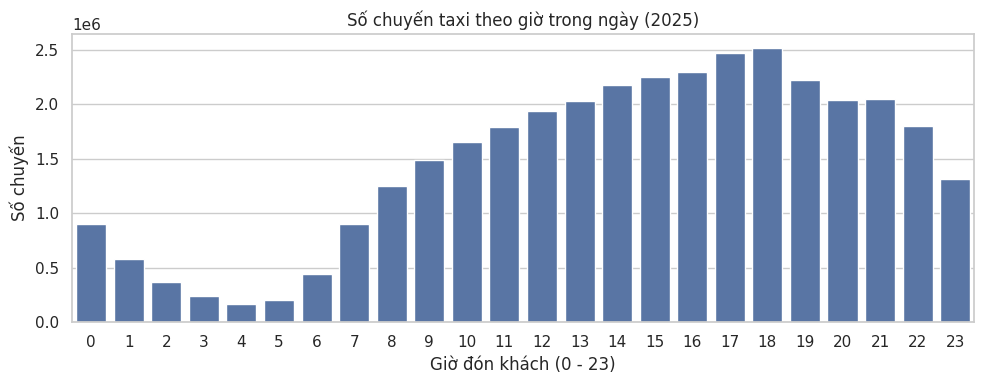

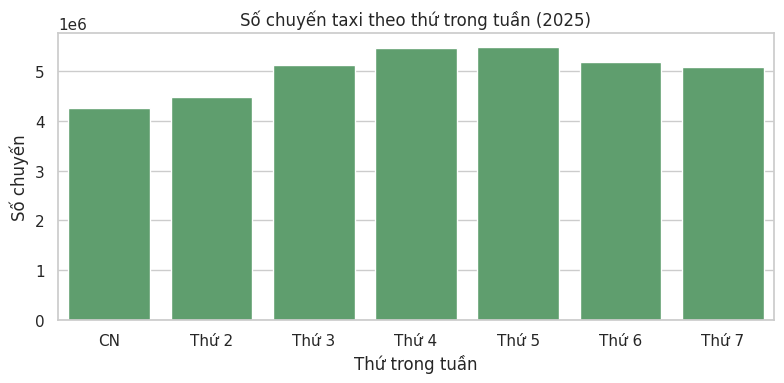

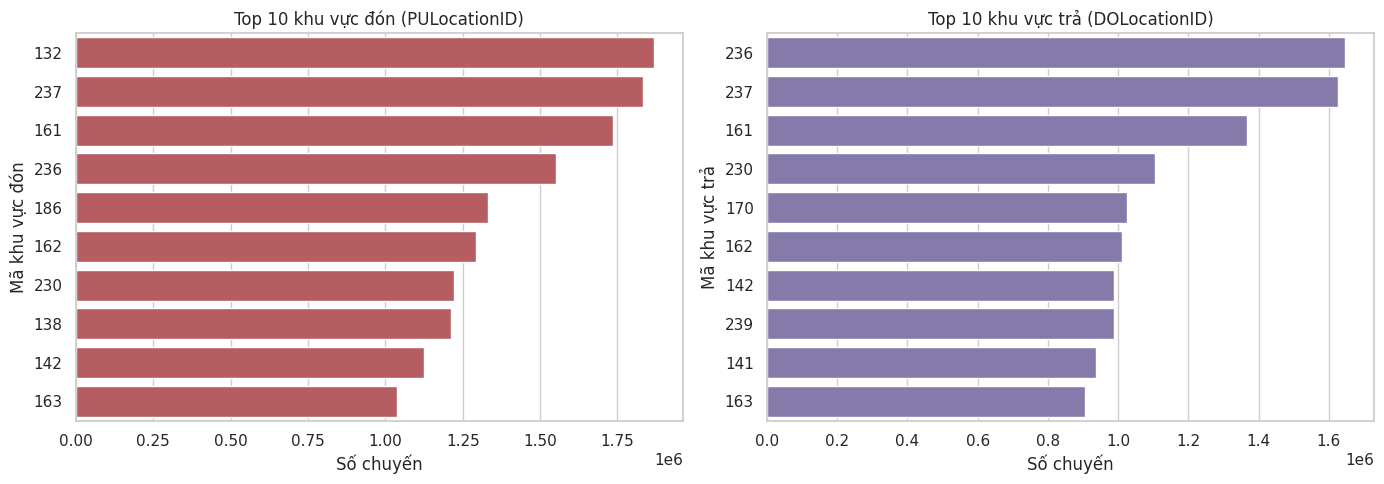

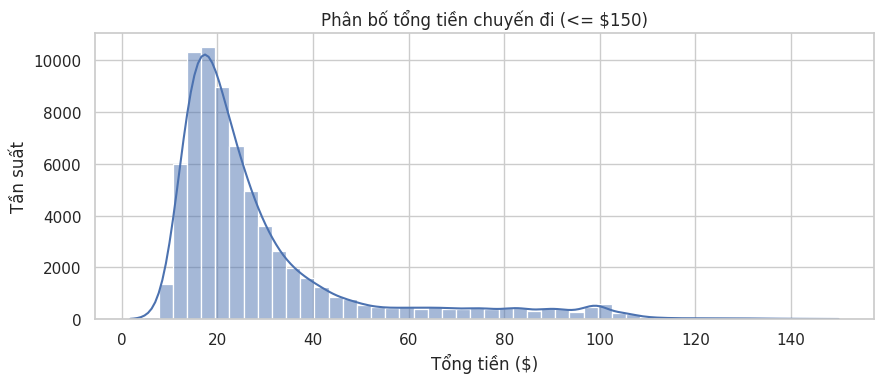

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid")
out_sql = "/content/drive/MyDrive/DoAnBigData/ket_qua_sql"
img_dir = "/content/drive/MyDrive/DoAnBigData/bieu_do"
os.makedirs(img_dir, exist_ok=True)

# 1. Số chuyến theo giờ
pdf_gio = pd.read_csv(f"{out_sql}/theo_gio.csv")
plt.figure(figsize=(10, 4))
sns.barplot(data=pdf_gio, x="pickup_hour", y="trip_count", color="#4C72B0")
plt.title("Số chuyến taxi theo giờ trong ngày (2025)")
plt.xlabel("Giờ đón khách (0 - 23)")
plt.ylabel("Số chuyến")
plt.tight_layout()
plt.savefig(f"{img_dir}/chuyen_theo_gio.png", dpi=300)
plt.show()

# 2. Số chuyến theo thứ trong tuần
dow_map = {1: "CN", 2: "Thứ 2", 3: "Thứ 3", 4: "Thứ 4", 5: "Thứ 5", 6: "Thứ 6", 7: "Thứ 7"}
pdf_thu = pd.read_csv(f"{out_sql}/theo_thu.csv")
pdf_thu["ten_thu"] = pdf_thu["day_of_week"].map(dow_map)

plt.figure(figsize=(8, 4))
sns.barplot(data=pdf_thu, x="ten_thu", y="trip_count", color="#55A868")
plt.title("Số chuyến taxi theo thứ trong tuần (2025)")
plt.xlabel("Thứ trong tuần")
plt.ylabel("Số chuyến")
plt.tight_layout()
plt.savefig(f"{img_dir}/chuyen_theo_thu.png", dpi=300)
plt.show()

# 3. Top 10 khu vực đón & trả
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pdf_pu = pd.read_csv(f"{out_sql}/top_pu.csv")
pdf_do = pd.read_csv(f"{out_sql}/top_do.csv")

sns.barplot(data=pdf_pu, x="pickup_count", y=pdf_pu["PULocationID"].astype(str), ax=axes[0], color="#C44E52")
axes[0].set_title("Top 10 khu vực đón (PULocationID)")
axes[0].set_xlabel("Số chuyến")
axes[0].set_ylabel("Mã khu vực đón")

sns.barplot(data=pdf_do, x="dropoff_count", y=pdf_do["DOLocationID"].astype(str), ax=axes[1], color="#8172B2")
axes[1].set_title("Top 10 khu vực trả (DOLocationID)")
axes[1].set_xlabel("Số chuyến")
axes[1].set_ylabel("Mã khu vực trả")

plt.tight_layout()
plt.savefig(f"{img_dir}/top_khu_vuc.png", dpi=300)
plt.show()

# 4. Phân bố tổng tiền chuyến đi (lấy mẫu nhỏ để vẽ nhanh)
pdf_gia = (
    bang.select("total_amount")
    .filter(F.col("total_amount") <= 150)
    .sample(fraction=0.002, seed=42)
    .toPandas()
)
plt.figure(figsize=(9, 4))
sns.histplot(pdf_gia["total_amount"], bins=50, kde=True, color="#4C72B0")
plt.title("Phân bố tổng tiền chuyến đi (<= $150)")
plt.xlabel("Tổng tiền ($)")
plt.ylabel("Tần suất")
plt.tight_layout()
plt.savefig(f"{img_dir}/phan_bo_gia_cuoc.png", dpi=300)
plt.show()

Huấn luyện & Đánh giá Linear Regression và Random Forest (Bài toán 2)

In [18]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

# Lấy mẫu 20% để huấn luyện gọn trên Colab, giữ nguyên tập lớn cho SQL
df_ml = (
    bang.sample(fraction=0.2, seed=42)
    .withColumn("pickup_hour", F.hour("tpep_pickup_datetime"))
    .withColumn("pickup_dayofweek", F.dayofweek("tpep_pickup_datetime"))
    .select(
        "trip_distance",
        "pickup_hour",
        "pickup_dayofweek",
        "passenger_count",
        "PULocationID",
        F.col("total_amount").cast("double").alias("label")
    )
)

feature_cols = ["trip_distance", "pickup_hour", "pickup_dayofweek", "passenger_count", "PULocationID"]
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
df_vec = assembler.transform(df_ml).select("features", "label")

train_df, test_df = df_vec.randomSplit([0.8, 0.2], seed=42)
train_df.cache()
test_df.cache()

lr = LinearRegression(featuresCol="features", labelCol="label")
lr_model = lr.fit(train_df)
lr_pred = lr_model.transform(test_df)

rf = RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=30, maxDepth=8, seed=42)
rf_model = rf.fit(train_df)
rf_pred = rf_model.transform(test_df)

ev_rmse = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")
ev_r2 = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="r2")

ket_qua_ml = spark.createDataFrame(
    [
        ("Linear Regression", float(ev_rmse.evaluate(lr_pred)), float(ev_r2.evaluate(lr_pred))),
        ("Random Forest Regressor", float(ev_rmse.evaluate(rf_pred)), float(ev_r2.evaluate(rf_pred))),
    ],
    ["Model", "RMSE", "R2"]
)
ket_qua_ml.show(truncate=False)
ket_qua_ml.toPandas().to_csv("/content/drive/MyDrive/DoAnBigData/ket_qua_sql/mllib_metrics.csv", index=False)

+-----------------------+-----------------+------------------+
|Model                  |RMSE             |R2                |
+-----------------------+-----------------+------------------+
|Linear Regression      |9.255249051375692|0.83822061849783  |
|Random Forest Regressor|9.604453742818098|0.8257822944971769|
+-----------------------+-----------------+------------------+

